In [1]:
import pandas as pd

cols = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df = pd.read_csv('4) house Prediction Data Set.csv', header=None, sep=r'\s+', names=cols)
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


## Exploring the data
Looking at summary statistics, correlations with price, and scatter plots before modelling, to understand what relationships the model should find

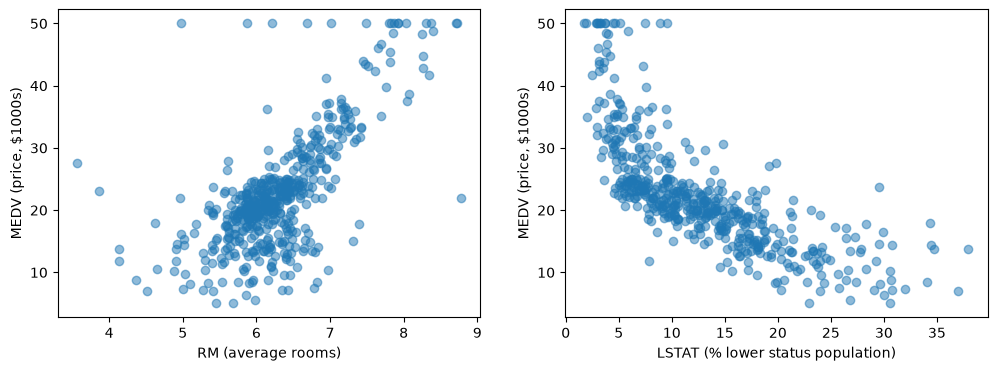

In [ ]:
df.describe()
df.corr()['MEDV'].sort_values(ascending=False)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df['RM'], df['MEDV'], alpha=0.5)
axes[0].set_xlabel('RM (average rooms)')
axes[0].set_ylabel('MEDV (price, $1000s)')

axes[1].scatter(df['LSTAT'], df['MEDV'], alpha=0.5)
axes[1].set_xlabel('LSTAT (% lower status population)')
axes[1].set_ylabel('MEDV (price, $1000s)')

plt.show()

## Preprocessing
Checking for missing values, splitting into train/test sets (80/20), then scaling
features. The scaler is fit on training data only to avoid data leakage.

In [5]:
print("Total missing values: ", df.isnull().sum().sum())

Total missing values:  0


In [6]:
from sklearn.model_selection import train_test_split

x = df.drop('MEDV', axis=1)
y = df['MEDV']

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape)



(404, 13) (102, 13)


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## Training the model
Fitting a Linear Regression model, which learns one coefficient per feature plus
an intercept by minimizing squared error on the training data.

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train_scaled, y_train)
print("Intercept:", round(model.intercept_, 3))

Intercept: 22.797


## Interpreting the coefficients
Each coefficient is the change in predicted price (in $1000s) for a one standard
deviation increase in that feature, holding all other features constant.
Larger absolute values mean stronger influence.

In [10]:
coef_df = pd.DataFrame({'Feature' : x.columns, 'Coefficient': model.coef_})
coef_df = coef_df.sort_values('Coefficient', key=abs, ascending=False)
coef_df

,Feature,Coefficient
12,LSTAT,-3.611658
5,RM,3.145240
7,DIS,-3.081908
8,RAD,2.251407
10,PTRATIO,-2.037752
4,NOX,-2.022319
9,TAX,-1.767014
11,B,1.129568
0,CRIM,-1.002135
3,CHAS,0.718738


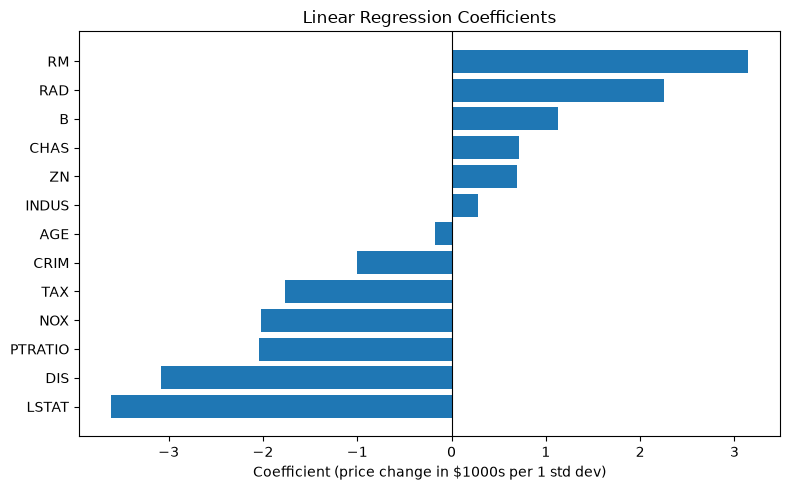

In [15]:
coef_sorted = coef_df.sort_values('Coefficient')
plt.figure(figsize=(8, 5))
plt.barh(coef_sorted['Feature'], coef_sorted['Coefficient'])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (price change in $1000s per 1 std dev)')
plt.title('Linear Regression Coefficients')
plt.tight_layout()

In [13]:
model_raw = LinearRegression().fit(x_train, y_train)
pd.Series(model_raw.coef_, index=x.columns).round(3)

CRIM       -0.113
ZN          0.030
INDUS       0.040
CHAS        2.784
NOX       -17.203
RM          4.439
AGE        -0.006
DIS        -1.448
RAD         0.262
TAX        -0.011
PTRATIO    -0.915
B           0.012
LSTAT      -0.509
dtype: float64

## Evaluation
- **R²**: share of price variation the model explains (1.0 = perfect).
- **MSE**: average squared prediction error; RMSE is its square root, in $1000s.
Comparing train and test scores checks for overfitting.

In [16]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

y_train_pred = model.predict(x_train_scaled)
y_test_pred = model.predict(x_test_scaled)

print("Train R²: ", round(r2_score(y_train, y_train_pred), 4))
print("Test R²:  ", round(r2_score(y_test, y_test_pred), 4))
print("Train MSE:", round(mean_squared_error(y_train, y_train_pred), 3))
print("Test MSE: ", round(mean_squared_error(y_test, y_test_pred), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 3))


Train R²:  0.7509
Test R²:   0.6688
Train MSE: 21.641
Test MSE:  24.291
Test RMSE: 4.929


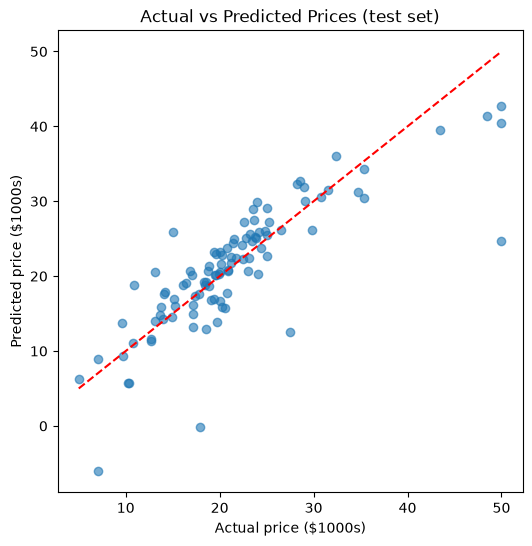

In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_test_pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual price ($1000s)')
plt.ylabel('Predicted price ($1000s)')
plt.title('Actual vs Predicted Prices (test set)')
plt.show()



## Conclusion
- The model achieved a **test R² of 0.669** and **test MSE of 24.29** (RMSE ≈ $4,929).
- The strongest predictors were `LSTAT` (negative) and `RM` (positive).
- Train R² (0.751) and test R² (0.669) are close, so overfitting is not severe.
- **Limitations:** 16 houses have prices capped at exactly $50k in the original data,
  which distorts the high end. Linear regression also assumes straight-line
  relationships, and the actual-vs-predicted plot suggests some curvature it misses.
  The `B` feature is derived from racial demographics, and this dataset was removed
  from scikit-learn over ethical concerns about that variable; it is used here only
  because it was supplied for the task.